# Invertibility of MA Models

An MA model $X_t=\theta(B)\varepsilon_t$ is invertible when $\varepsilon_t=\theta(B)^{-1}X_t=\sum_k\pi_kX_{t-k}$ with summable weights, equivalently when all roots of $\theta(z)$ lie outside the unit circle. This notebook computes inverse weights, checks roots, shows that $\theta$ and $1/\theta$ share an ACF, and recovers innovations from data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(40)

def inverse_weights(theta, J=15):
    """pi_k of theta(B)^{-1}: pi_0=1, pi_k = -sum_j theta_j pi_{k-j}."""
    q = len(theta)
    pi = np.zeros(J)
    pi[0] = 1.0
    for k in range(1, J):
        pi[k] = -sum(theta[j - 1] * pi[k - j] for j in range(1, min(k, q) + 1))
    return pi

for th in (0.5, 2.0):
    print(f"theta={th}:", np.round(inverse_weights([th], 8), 3))

theta=0.5: [ 1.    -0.5    0.25  -0.125  0.062 -0.031  0.016 -0.008]
theta=2.0: [   1.   -2.    4.   -8.   16.  -32.   64. -128.]


For $\theta=0.5$ the weights $1,-0.5,0.25,\dots$ decay; for $\theta=2$ they grow as $1,-2,4,-8,\dots$, so the past-based inverse is explosive.

In [2]:
def ma_roots(theta):
    # numpy.roots wants the highest power first
    return np.roots(np.r_[theta[::-1], 1.0])

for theta in ([0.5], [2.0], [0.5, 0.3], [0.4, -0.9]):
    r = ma_roots(np.array(theta))
    print(theta, "moduli:", np.round(np.abs(r), 3), "-> invertible:", bool(np.all(np.abs(r) > 1)))

[0.5] moduli: [2.] -> invertible: True
[2.0] moduli: [0.5] -> invertible: False
[0.5, 0.3] moduli: [1.826 1.826] -> invertible: True
[0.4, -0.9] moduli: [1.299 0.855] -> invertible: False


The MA(2) with $\theta=(0.5,0.3)$ has complex roots of modulus $1/\sqrt{0.3}\approx1.826$, as in the note. The pair $(0.4,-0.9)$ has a root of modulus about $0.86$ inside the unit circle even though both $|\theta_j|<1$, so the root check, not a coefficient bound, is the right general criterion.

In [3]:
# theta and 1/theta give the same autocorrelation
for th in (0.5, 2.0):
    print(f"theta={th}: rho(1) = {th / (1 + th**2):.4f}")

# the invertible representative is what simulation-based software returns
theta = 0.5
eps = rng.normal(size=2000)
x = eps[1:] + theta * eps[:-1]
rec = np.zeros(len(x))
for t in range(len(x)):               # eps_t = x_t - theta * eps_{t-1}, with eps_{-1}=0
    rec[t] = x[t] - theta * (rec[t - 1] if t else 0.0)
err = np.abs(rec - eps[1:])
print("recovery error at t=0,5,20,100:", np.round(err[[0, 5, 20, 100]], 6))

theta=0.5: rho(1) = 0.4000
theta=2.0: rho(1) = 0.4000
recovery error at t=0,5,20,100: [5.71046e-01 1.78450e-02 1.00000e-06 0.00000e+00]


Because $\rho(1)=0.4$ for both $0.5$ and $2$, second moments cannot distinguish them; invertibility selects $|\theta|<1$. When $|\theta|<1$ the recursive filter forgets its starting error geometrically (error is multiplied by $\theta$ each step).

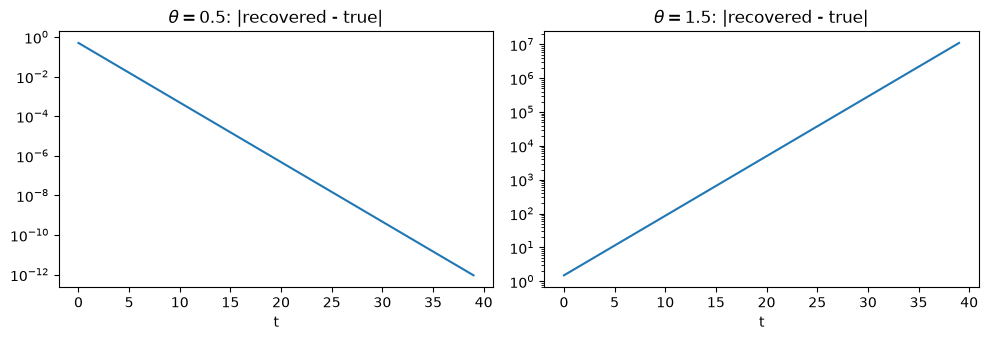

In [4]:
# Starting-value error is damped when |theta|<1 and amplified when |theta|>1
def recover(theta, x, e0=1.0):
    out, prev = [], e0
    for v in x:
        prev = v - theta * prev
        out.append(prev)
    return np.array(out)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, th in zip(ax, (0.5, 1.5)):
    e = rng.normal(size=40)
    x = e + th * np.r_[0.0, e[:-1]]
    a.semilogy(np.abs(recover(th, x) - e) + 1e-16)
    a.set_title(rf"$\theta={th}$: |recovered - true|")
    a.set_xlabel("t")
plt.tight_layout(); plt.show()